# Figure 5

Panels F and G: LPTC response under pair and individual silencing of Tm1, Tm2, Tm4 and Tm9, and SNR of the circuit left active.

**Data.** `Data_digitized/Serbe2016_LPTC.csv` and `Data_digitized/Serbe2016_LPTC_std.csv` hold the normalized peak LPTC responses and their error bars, digitized from the silencing figure of Serbe et al., *Neuron* 89 (2016) (bar ends and error-whisker ends; single silencing on the diagonal of their matrix, pair silencing above it).

**Precomputed SNR.** SNR of the OFF medulla pairs and triplets, in `PrecomputedSNR/` (`snrF_dtfix_*.pkl`, `snrF3_dtfix_*.pkl`); `Fig3_1_SNR_vs_TemporalDiversity.ipynb` writes them if they are missing.

**SNR code.** All functions to compute the SNR (Eqs. 20, 21) are in `Fig3_1_SNR_vs_TemporalDiversity.ipynb`; its `snr_circuit` computes the SNR of any circuit, so the precomputed SNR can be reproduced from there.

**Fit parameters.** The cache names are keyed on the sha256 of `FitParameters/GeneratedFilters_Inverse_UnconstrainedFit_GaussianDistributed.txt`.

In [1]:
import hashlib
import pickle
from itertools import combinations_with_replacement
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import pearsonr

matplotlib.rcParams['font.family']     = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Arial']
matplotlib.rcParams['font.size']       = 12
matplotlib.rcParams['pdf.fonttype']    = 42
matplotlib.rcParams['ps.fonttype']     = 42

# Paths
PATH_CACHE     = Path('PrecomputedSNR')
PATH_DIGITIZED = Path('Data_digitized')
PATH_PARAMS    = Path('FitParameters')
PATH_PDF       = Path('Pdf_figures')
PATH_PDF.mkdir(exist_ok=True)

In [2]:
C_ACTIVE, C_SILENCED = '#d95f02', 'k'

AX_RIGHT = 0.15

def fixed_axes(ax_w, ax_h, left, bottom, top=0.12):
    # axes of ax_w x ax_h inches
    W, H = left + ax_w + AX_RIGHT, bottom + ax_h + top
    fig = plt.figure(figsize=(W, H))
    return fig, fig.add_axes([left / W, bottom / H, ax_w / W, ax_h / H])

## LPTC responses

In [3]:
NEURONS = ['Tm1', 'Tm2', 'Tm4', 'Tm9']

# silenced neurons of each digitized bar, in file order
SILENCED = [('Tm1',), ('Tm2',), ('Tm4',), ('Tm9',),
            ('Tm1', 'Tm2'), ('Tm1', 'Tm4'), ('Tm1', 'Tm9'),
            ('Tm2', 'Tm4'), ('Tm2', 'Tm9'),
            ('Tm4', 'Tm9')]

def bar_lengths(fname):
    y = pd.read_csv(PATH_DIGITIZED / fname, header=None).values[:, 1]
    return np.abs(y[1::2] - y[::2])

response = bar_lengths('Serbe2016_LPTC.csv') / 100     # fraction of control
error    = bar_lengths('Serbe2016_LPTC_std.csv') / 2   # half the whisker span

serbe = pd.DataFrame({'silenced': SILENCED, 'response': response, 'error': error})
serbe['active'] = [tuple(n for n in NEURONS if n not in s) for s in serbe['silenced']]
serbe['n_silenced'] = serbe['silenced'].map(len)
serbe = serbe.sort_values(['n_silenced', 'response'], ascending=[False, True]).reset_index(drop=True)

## Fig. 5F

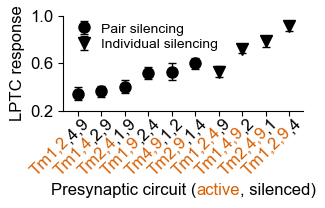

In [4]:
def colored_text(ax, pieces, xy, transform, angle=0, align='center', **kw):
    # [(string, colour), ...] written as one line at xy
    fig = ax.figure
    renderer = fig.canvas.get_renderer()
    widths = []
    for s, _ in pieces:
        t = ax.text(0, 0, s, **kw)
        widths.append(t.get_window_extent(renderer).width * 72 / fig.dpi)   # points
        t.remove()
    d = np.array([np.cos(np.radians(angle)), np.sin(np.radians(angle))])
    pos = -sum(widths) / 2 if align == 'center' else -sum(widths)
    texts = []
    for (s, c), w in zip(pieces, widths):
        texts.append(ax.annotate(s, xy, xycoords=transform, xytext=pos * d, textcoords='offset points',
                                 color=c, rotation=angle, rotation_mode='anchor', ha='left', va='top',
                                 annotation_clip=False, **kw))
        pos += w
    return texts

def circuit_label(active, silenced):
    num = lambda ns: ','.join(n[2:] for n in ns)
    return [('Tm' + num(active), C_ACTIVE), (',' + num(silenced), C_SILENCED)]

def plot_lptc_vs_circuit(df, ax_w=2.4, ax_h=0.95, save=None):
    x = np.arange(len(df))
    fig, ax = fixed_axes(ax_w, ax_h, left=0.62, bottom=1.0, top=0.25)

    for n_off, marker, label in [(2, 'o', 'Pair silencing'), (1, 'v', 'Individual silencing')]:
        m = (df['n_silenced'] == n_off).values
        ax.errorbar(x[m], df['response'][m], yerr=df['error'][m], linestyle='none', marker=marker,
                    markersize=8, color='k', capsize=3, lw=1, label=label)
    ax.legend(frameon=False, loc='upper left', fontsize=10, handletextpad=0.2, labelspacing=0.2,
              borderaxespad=0.1)
    ax.set_ylim(0.2, 1.0)
    ax.set_yticks([0.2, 0.6, 1.0])
    ax.set_xlim(-0.6, len(df) - 0.4)
    ax.set_ylabel('LPTC response')
    ax.spines[['top', 'right']].set_visible(False)

    ax.set_xticks(x, [''] * len(df))
    for xi, a, s in zip(x, df['active'], df['silenced']):
        colored_text(ax, circuit_label(a, s), (xi + 0.15, -0.04), ax.get_xaxis_transform(),
                     angle=45, align='end')

    fig.canvas.draw()
    to_axes = ax.transAxes.inverted()
    bottom = min(to_axes.transform(t.get_window_extent().p0)[1] for t in ax.texts)
    colored_text(ax, [('Presynaptic circuit (', 'k'), ('active', C_ACTIVE), (', silenced)', 'k')],
                 (0.5, bottom - 0.05), ax.transAxes)

    if save:
        fig.savefig(PATH_PDF / save)
    plt.show()
    return ax

ax_F = plot_lptc_vs_circuit(serbe, save='Fig5F_LPTC_vs_Circuit_Serbe2016.pdf')

## SNR of the active circuit

In [5]:
GEN_FILTERS = 'GeneratedFilters_Inverse_UnconstrainedFit_GaussianDistributed.txt'

# circuit order of the caches
CIRCUITS = {'Lamina':      ['L1', 'L2', 'L3'],
            'ON Medulla':  ['Mi1', 'Mi9', 'Tm3', 'Mi4'],
            'OFF Medulla': ['Tm2', 'Tm1', 'Tm4', 'Tm9']}
BANDS      = ['III', 'LF', 'F', 'E', 'I', 'A', 'B', 'II']
NOISE_GRID = np.geomspace(1e-3, 1e1, 25)       # sigma_N^2 / var(s_ref)
K, SIGMA_N2 = -1.6, 2.15

def load_snr(m):
    # -> {sorted tuple of neurons: SNR} for every m-neuron circuit
    tag = hashlib.sha256(open(PATH_PARAMS / GEN_FILTERS, 'rb').read()).hexdigest()[:12]
    stem, suff = {2: ('snrF', 'p'), 3: ('snrF3', 't')}[m]
    labels = [t for ns in CIRCUITS.values() for t in combinations_with_replacement(ns, m)]
    log_snr = np.mean([pickle.load(open(PATH_CACHE / f'{stem}_dtfix_{tag}_a{-K:g}_band{b}_'
                                        f'{len(NOISE_GRID)}n_{len(labels)}{suff}.pkl', 'rb'))
                       for b in BANDS], axis=0)                     # (noise, circuits, filter draws)
    i = int(np.argmin(np.abs(NOISE_GRID - SIGMA_N2)))
    snr = np.exp(np.mean(log_snr[i], axis=1))                       # geometric mean over bands and draws
    return {tuple(sorted(t)): s for t, s in zip(labels, snr)}

SNR = {**load_snr(2), **load_snr(3)}
serbe['snr'] = [SNR[tuple(sorted(a))] for a in serbe['active']]

## Fig. 5G

pair silencing        Pearson r = 0.896, p = 0.016, n = 6
individual silencing  Pearson r = 0.899, p = 0.101, n = 4


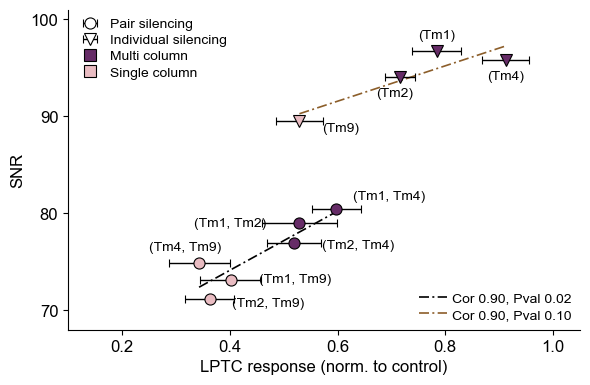

In [6]:
FIT_STYLE = (0, (6, 2, 1.2, 2))
FIT_COLOR = {2: 'k', 1: '#8c5e2a'}            # keyed by number of silenced neurons
GROUPS    = [(2, 'o', 'Pair silencing'), (1, 'v', 'Individual silencing')]

COLOR_COLUMN = {'multi': '#662c67', 'single': '#e9bcc2'}
COLUMN_LABEL = {'multi': 'Multi column', 'single': 'Single column'}
COLUMN_OF    = {'Tm9': 'C1', 'Tm1': 'C2', 'Tm2': 'C2', 'Tm4': 'C2'}

def column_class(active):
    return 'single' if len({COLUMN_OF[n] for n in active}) == 1 else 'multi'

# label offset from the marker, in points
LABEL_OFFSET = {('Tm4', 'Tm9'): (-10, 11), ('Tm2', 'Tm9'): (16, -3), ('Tm1', 'Tm9'): (20, 0),
                ('Tm2', 'Tm4'): (20, -2),  ('Tm1', 'Tm2'): (-24, 0), ('Tm1', 'Tm4'): (12, 9),
                ('Tm9',): (16, -5), ('Tm2',): (-4, -12), ('Tm1',): (0, 11), ('Tm4',): (0, -12)}

G_ASPECT = 1.6

def plot_snr_vs_lptc(df, ax_h=3.2, aspect=G_ASPECT, save=None):
    fig, ax = fixed_axes(aspect * ax_h, ax_h, left=0.62, bottom=0.55)
    marker_handles = []
    for n_off, marker, label in GROUPS:
        g = df[df['n_silenced'] == n_off]
        for cls in ('multi', 'single'):
            h = g[[column_class(a) == cls for a in g['active']]]
            ax.errorbar(h['response'], h['snr'], xerr=h['error'], linestyle='none', marker=marker,
                        markersize=8, color='k', markerfacecolor=COLOR_COLUMN[cls], markeredgecolor='k',
                        markeredgewidth=0.8, capsize=3, lw=1, zorder=3)
        marker_handles.append(ax.errorbar([np.nan], [np.nan], xerr=[0.05], linestyle='none', marker=marker, markersize=8,
                                          color='k', markerfacecolor='white', markeredgecolor='k',
                                          markeredgewidth=0.8, capsize=3, lw=1, label=label))
    class_handles = [Line2D([], [], ls='none', marker='s', markersize=8, markerfacecolor=COLOR_COLUMN[k],
                            markeredgecolor='k', markeredgewidth=0.8, label=COLUMN_LABEL[k])
                     for k in ('multi', 'single')]

    # least-squares fit and Pearson r per silencing type
    fit_lines = []
    for n_off in (2, 1):
        g = df[df['n_silenced'] == n_off]
        b1, b0 = np.polyfit(g['response'], g['snr'], 1)
        xs = np.linspace(g['response'].min(), g['response'].max(), 50)
        r, p = pearsonr(g['response'], g['snr'])
        fit_lines += ax.plot(xs, b1 * xs + b0, ls=FIT_STYLE, color=FIT_COLOR[n_off], lw=1.2, zorder=2,
                             label=f'Cor {r:.2f}, Pval {p:.2f}')

    for _, r in df.iterrows():
        dx, dy = LABEL_OFFSET.get(r['silenced'], (6, 4))
        ax.annotate('(' + ', '.join(r['silenced']) + ')', (r['response'], r['snr']),
                    xytext=(dx, dy), textcoords='offset points', fontsize=10,
                    ha='left' if dx > 0 else 'right' if dy == 0 else 'center', va='center')

    ax.set_xlabel('LPTC response (norm. to control)')
    ax.set_ylabel('SNR')
    ax.set_xlim(0.1, 1.05)
    ax.set_ylim(68, 101)
    ax.set_yticks(range(70, 101, 10))
    ax.spines[['top', 'right']].set_visible(False)

    markers = ax.legend(handles=marker_handles + class_handles, loc='upper left', frameon=False, fontsize=10,
                        handletextpad=0.4, labelspacing=0.25, borderaxespad=0.2)
    ax.add_artist(markers)
    ax.legend(handles=fit_lines, loc='lower right', frameon=False, fontsize=10,
              handletextpad=0.4, labelspacing=0.25, borderaxespad=0.2)

    if save:
        fig.savefig(PATH_PDF / save)
    plt.show()
    return ax

for n_off, name in ((2, 'pair silencing'), (1, 'individual silencing')):
    g = serbe[serbe['n_silenced'] == n_off]
    r, p = pearsonr(g['response'], g['snr'])
    print(f'{name:21s} Pearson r = {r:.3f}, p = {p:.3f}, n = {len(g)}')
ax_G = plot_snr_vs_lptc(serbe, save='Fig5G_SNR_vs_LPTC_Serbe2016.pdf')